# 左右朝向的狗头特征：复现 Olah 的例子
使用原研究的 Lucid InceptionV1 与论文图中的 mixed4a:308、mixed4a:222；固定权重。左右方向按观看者视角。详细来源、图片许可和实验边界见 README。

## 1. 加载模型与实验函数
这里保留完整计算代码：prepare 下载并加载模型，measure 对比镜像图片的真实激活，synthesize 从随机 Fourier 参数优化图像。

In [1]:
import argparse
import hashlib
import json
import os
from pathlib import Path
import urllib.request

os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import numpy as np
from PIL import Image, ImageOps
import tensorflow as tf
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT/'experiment.py').exists():
    raise FileNotFoundError('请在 dog-direction 目录打开 Notebook')
CHANNELS = [308, 222]
MODEL_URL = 'https://storage.googleapis.com/modelzoo/vision/other_models/InceptionV1.pb'
PHOTO_URL = 'https://storage.googleapis.com/download.tensorflow.org/example_images/YellowLabradorLooking_new.jpg'


def prepare():
    (ROOT/'cache').mkdir(exist_ok=True)
    (ROOT/'results').mkdir(exist_ok=True)
    for name, url in [('InceptionV1.pb', MODEL_URL), ('labrador.jpg', PHOTO_URL)]:
        path = ROOT/'cache'/name
        if not path.exists():
            urllib.request.urlretrieve(url, path)
    graphdef = tf.compat.v1.GraphDef()
    graphdef.ParseFromString((ROOT/'cache/InceptionV1.pb').read_bytes())
    return graphdef


def measure(graphdef):
    photo = Image.open(ROOT/'cache/labrador.jpg').convert('RGB')
    variants = [('full', photo), ('head', photo.crop((20, 0, 310, 290))),
                ('head_wide', photo.crop((0, 0, 350, 350))),
                ('head_gray', ImageOps.grayscale(photo.crop((20, 0, 310, 290))).convert('RGB'))]
    flower = Image.open(ROOT.parent/'original.jpg').convert('RGB')
    variants.append(('flower_control', flower))
    images, labels = [], []
    for name, source in variants:
        for flipped in [False, True]:
            image = ImageOps.mirror(source) if flipped else source
            images.append(np.asarray(image.resize((224, 224)), dtype=np.float32))
            labels.append({'image':name, 'flipped':flipped})
    graph = tf.Graph()
    with graph.as_default():
        tf.import_graph_def(graphdef, name='')
    with tf.compat.v1.Session(graph=graph) as session:
        layers = session.run([graph.get_tensor_by_name(n+':0') for n in ['mixed4a', 'mixed4b']],
                            {'input:0':np.stack(images)-117})
    rows=[]
    for i, label in enumerate(labels):
        row=dict(label)
        for layer, values, channels in [('mixed4a', layers[0], CHANNELS), ('mixed4b', layers[1], [409, 418])]:
            for channel in channels:
                activation=values[i,:,:,channel]
                row[f'{layer}:{channel}']={'max':float(activation.max()),'mean':float(activation.mean())}
        rows.append(row)
    result={'model_url':MODEL_URL,'model_sha256':hashlib.sha256((ROOT/'cache/InceptionV1.pb').read_bytes()).hexdigest(),
            'source_photo':PHOTO_URL,'channels_selected_from':'Distill DogCircuit.svg mixed4a_308 and mixed4a_222',
            'statistic':'Spatial maximum of post-ReLU channel; mean also reported',
            'scope':'One natural dog photo, mirrored and cropped; crops are not independent dogs. No training or channel search.',
            'rows':rows}
    (ROOT/'results/measurements.json').write_text(json.dumps(result,indent=2))
    selected=[2,3]
    vmax=max(layers[0][i,:,:,c].max() for i in selected for c in CHANNELS)
    fig, axes=plt.subplots(2,3,figsize=(10,6.8),layout='constrained')
    for row,i in enumerate(selected):
        axes[row,0].imshow(images[i].astype('uint8'))
        axes[row,0].set_title('Head faces RIGHT' if row==0 else 'Same crop, mirrored: LEFT')
        for col,c in enumerate(CHANNELS,1):
            a=layers[0][i,:,:,c]
            axes[row,col].imshow(images[i].astype('uint8'),alpha=.38)
            heat=axes[row,col].imshow(a,cmap='magma',vmin=0,vmax=vmax,extent=(-.5,223.5,223.5,-.5),alpha=.8,interpolation='bilinear')
            axes[row,col].set_title(f'mixed4a:{c}\nmax activation = {a.max():.1f}')
        for ax in axes[row]:ax.axis('off')
    fig.colorbar(heat,ax=axes[:,1:],shrink=.6,label='Activation (shared scale)')
    fig.suptitle('Published dog-head channels respond differently to horizontal reflection')
    fig.savefig(ROOT/'results/direction-comparison.png',dpi=160)
    plt.close(fig)
    for row in rows:print(row,flush=True)
    return result


def synthesize(graphdef, steps=256):
    """Optimize Fourier image parameters for the published channels, no text prompt."""
    size=224
    rng=np.random.default_rng(42)
    fy=np.fft.fftfreq(size)[:,None];fx=np.fft.rfftfreq(size)[None,:]
    scale=1/np.maximum(np.sqrt(fx*fx+fy*fy),1/size)
    graph=tf.Graph()
    with graph.as_default():
        tf.compat.v1.set_random_seed(42)
        spectrum=tf.Variable(rng.normal(0,.01,(2,3,size,size//2+1,2)).astype('float32'))
        complex_values=tf.complex(spectrum[...,0],spectrum[...,1])*tf.constant(scale,dtype=tf.complex64)
        rgb=tf.transpose(tf.signal.irfft2d(complex_values),[0,2,3,1])*size
        image=tf.sigmoid(rgb)
        shift=tf.random.uniform([2],-8,9,dtype=tf.int32)
        jitter=tf.roll(image,shift=shift,axis=[1,2])
        tf.import_graph_def(graphdef,input_map={'input:0':jitter*255-117},name='net')
        acts=graph.get_tensor_by_name('net/mixed4a:0')
        # Optimize pre-ReLU values so an initially inactive channel has a gradient.
        branches=acts.op.inputs[1:]
        pre_relu=tf.concat([t.op.inputs[0] if t.op.type=='Relu' else t for t in branches],axis=-1)
        objectives=tf.stack([tf.reduce_mean(pre_relu[i,6:8,6:8,c]) for i,c in enumerate(CHANNELS)])
        loss=-tf.reduce_mean(objectives)
        train=tf.compat.v1.train.AdamOptimizer(.03).minimize(loss,var_list=[spectrum])
        init=tf.compat.v1.global_variables_initializer()
    config=tf.compat.v1.ConfigProto(intra_op_parallelism_threads=6,inter_op_parallelism_threads=2)
    with tf.compat.v1.Session(graph=graph,config=config) as session:
        session.run(init)
        for step in range(steps):
            _,score=session.run([train,objectives])
            if step%32==0:print('Synthesis',step,np.round(score,1),flush=True)
        pixels=session.run(image)
    fig,axes=plt.subplots(1,2,figsize=(8,4.3),layout='constrained')
    for i,c in enumerate(CHANNELS):
        im=Image.fromarray(np.uint8(np.clip(pixels[i]*255,0,255)))
        im.save(ROOT/f'results/feature-{c}.png')
        axes[i].imshow(im);axes[i].axis('off');axes[i].set_title(f'mixed4a:{c} | optimized from noise')
    fig.savefig(ROOT/'results/feature-comparison.png',dpi=160);plt.close(fig)



## 2. 真实照片与水平镜像
分别测量原始整图、狗头裁剪、扩大裁剪及灰度裁剪；花卉为对照。这些狗图均来自同一张照片。

{'image': 'full', 'flipped': False, 'mixed4a:308': {'max': 785.5859375, 'mean': 37.53459930419922}, 'mixed4a:222': {'max': 454.84857177734375, 'mean': 25.38026237487793}, 'mixed4b:409': {'max': 495.0093078613281, 'mean': 42.335296630859375}, 'mixed4b:418': {'max': 1120.97802734375, 'mean': 46.78305435180664}}
{'image': 'full', 'flipped': True, 'mixed4a:308': {'max': 456.2459716796875, 'mean': 28.72974395751953}, 'mixed4a:222': {'max': 667.3217163085938, 'mean': 32.45918273925781}, 'mixed4b:409': {'max': 534.0365600585938, 'mean': 43.3710823059082}, 'mixed4b:418': {'max': 1059.8896484375, 'mean': 41.02519226074219}}
{'image': 'head', 'flipped': False, 'mixed4a:308': {'max': 789.7232666015625, 'mean': 28.240787506103516}, 'mixed4a:222': {'max': 378.3680419921875, 'mean': 11.166844367980957}, 'mixed4b:409': {'max': 1051.2947998046875, 'mean': 83.62649536132812}, 'mixed4b:418': {'max': 620.1318969726562, 'mean': 23.144441604614258}}
{'image': 'head', 'flipped': True, 'mixed4a:308': {'max':

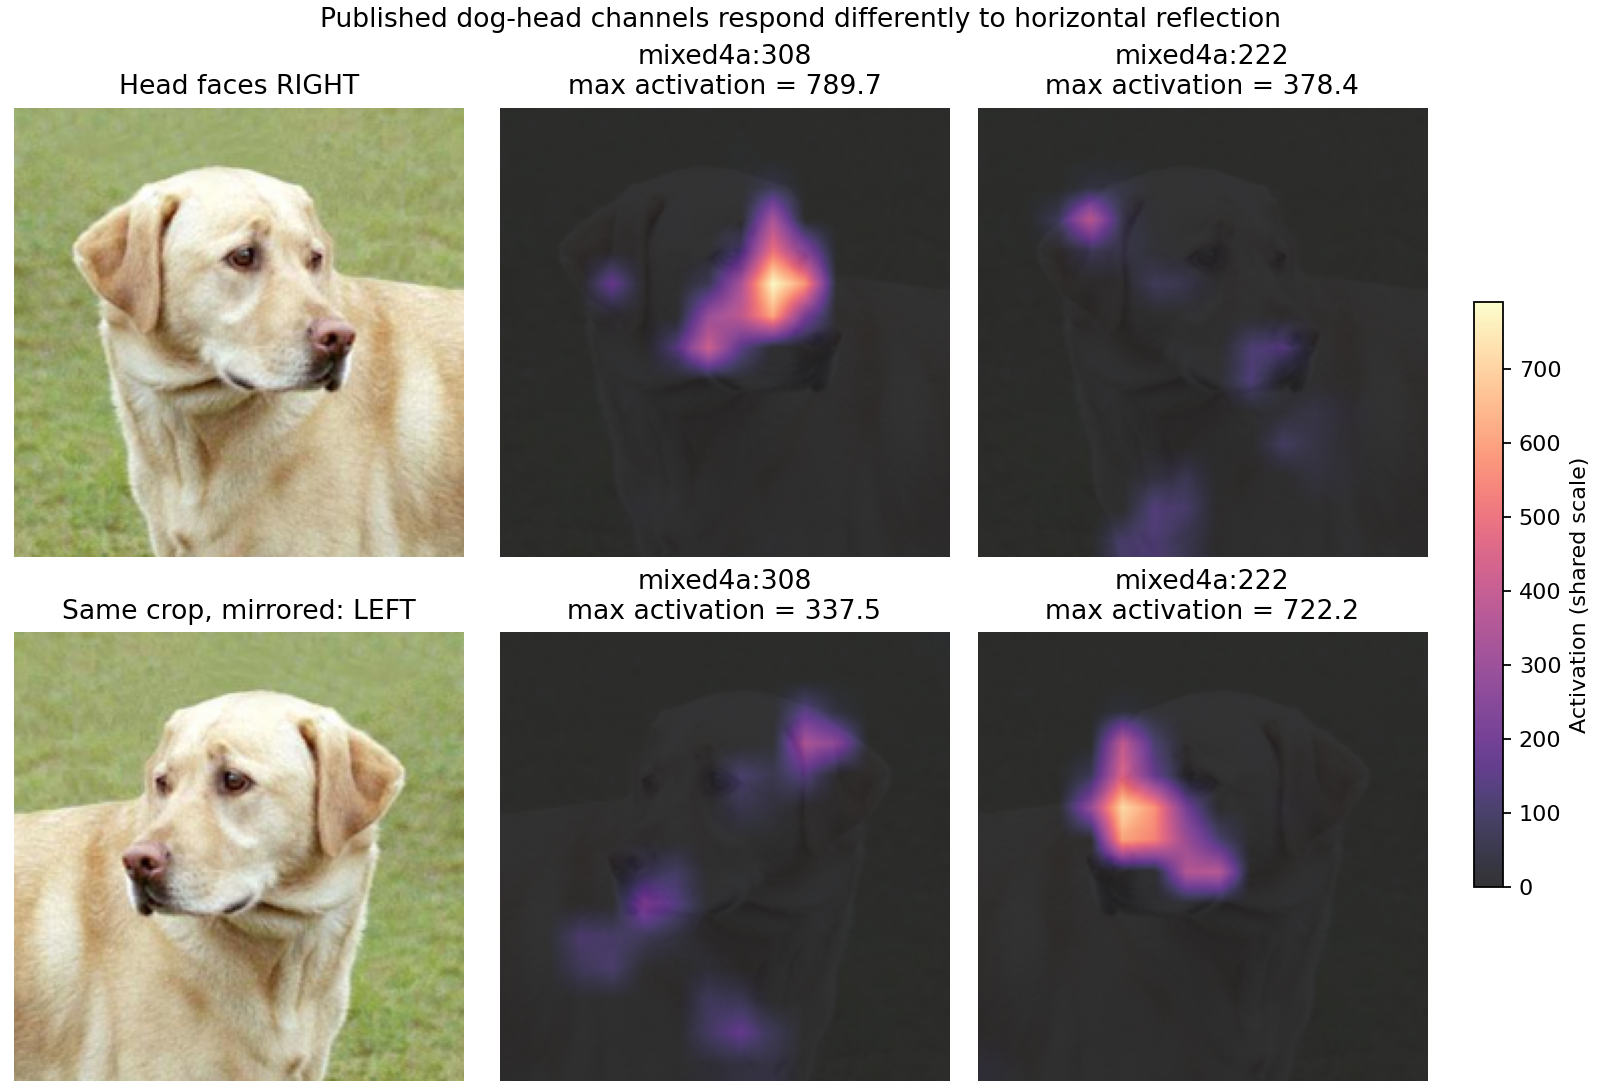

In [2]:
from IPython.display import display
graphdef=prepare()
measurements=measure(graphdef)
display(Image.open(ROOT/'results/direction-comparison.png'))

## 3. 从随机噪声合成单通道偏好的图像
对两个指定通道的中心激活求图片梯度。使用 pre-ReLU 目标避免起始时神经元未激活而无法优化；不会更新模型参数。

Synthesis 0 [-60.5 -65.7]
Synthesis 32 [1195.1 1478.7]
Synthesis 64 [2227.6 2363.6]
Synthesis 96 [2257.3 2238.2]
Synthesis 128 [2528.2 2569. ]
Synthesis 160 [2171.6 2328.8]
Synthesis 192 [2666.4 2683.4]
Synthesis 224 [2539.9 2589.3]
<PIL.PngImagePlugin.PngImageFile image mode=RGBA size=1280x688 at 0x3002EDA90>


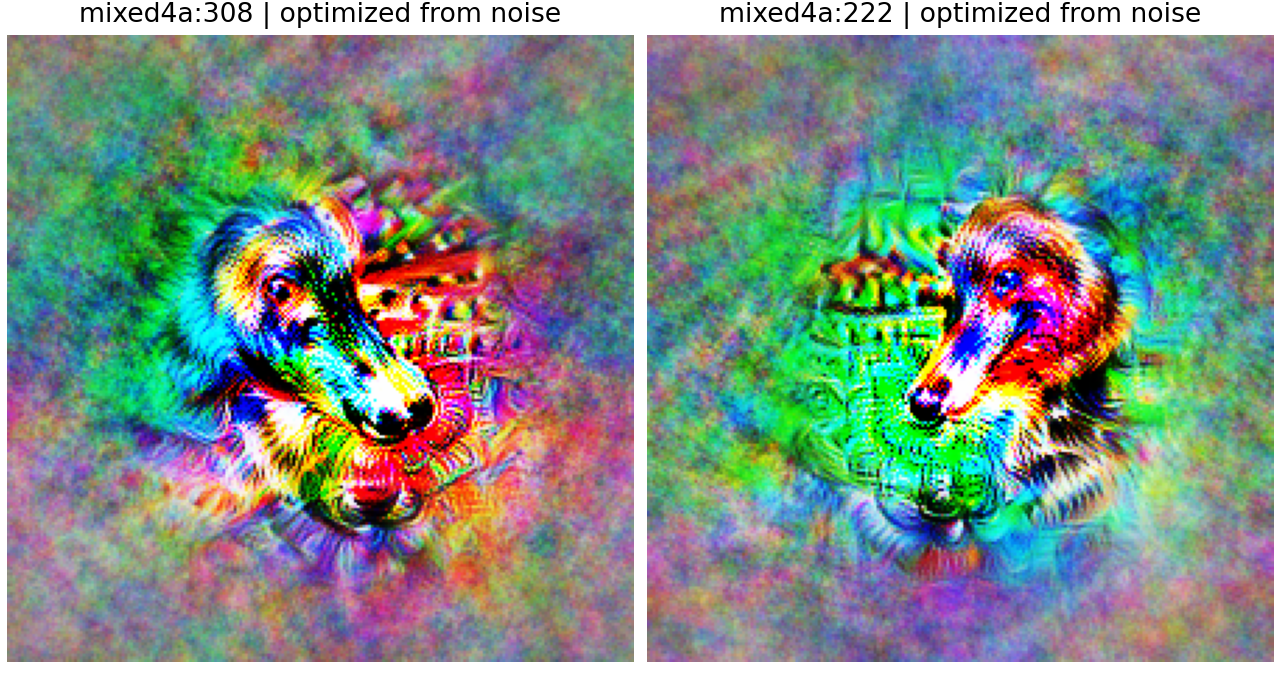

In [3]:
synthesize(graphdef,steps=256)
display(Image.open(ROOT/'results/feature-comparison.png'))

## 结论范围
本次是原论文指定单元的方向偏好复现，包含一张真实狗照片及其变换、单通道特征可视化。完整通路的兴奋与抑制机制需要额外的消融或权重干预。本次没有测量跨犬种泛化准确率。